# Statistical comparisons: parameter estimation
Both seeds; $M=2^{19}$; transformer training context 128. Each curve uses the **same first 256 test examples per seed** at every inference context. No transformer training or inference is rerun: its saved errors/predictions are loaded, and its noisy inputs are regenerated and checked against saved targets.

Bounded MLE minimizes normalized trajectory residuals (the Gaussian noise likelihood). Nonlinear fits use multiple starts; this is a numerical approximation, not a certificate of a global maximum. Projected SGD uses random observation minibatches, a decaying step size, and the prior midpoint initialization, with no access to the true parameter. Its finite optimization budget is editable below. Diagnostics distinguish optimization failure from statistical error.

For both separate and joint transformers, predictions are averaged over tokens first, then squared error is averaged over normalized parameter coordinates (L_mean). Statistical procedures also return one parameter estimate per dataset. Birth–death compares the physical identifiable pair $(b-d,c)$ from the transformer's **mean output**; individual-token combination error cannot be recovered from these caches. Bands use 5,000 whole-trajectory resamples to form approximate pointwise 95% percentile-bootstrap confidence intervals for mean test error, not across-seed uncertainty. Curves average the two seed-specific risks; colors distinguish estimators.

The optional posterior curves use the posterior mean under the original uniform parameter-box prior and Gaussian noise likelihood. Forced linear uses randomized importance quadrature. Nonlinear families combine proposals near multiple likelihood fits with a defensive uniform-prior proposal covering the full parameter box; Stuart-Landau fits probe several initial frequencies. Each trajectory's estimate and diagnostics are cached. Checks require small integration error across independent scrambles, agreement of means and variances at increasing sample counts, two stable refinements, sufficient effective sample size, and no dominating weight. Birth-death integrates over the full original (birth, death, competition) prior and monitors the identifiable pair as well as individual parameters; every final plotted birth-death error uses the identifiable pair. Numerical checks cannot prove every posterior mode has been found.

Plots use equal-weight averages across the two trained seeds (errors, not predictions). Test-error bands are within-seed bootstrap intervals for this average, conditional on the trained models, not across-training-seed confidence intervals. Original figure filenames are retained.

The MSE comparisons use only training n=128, including the joint model’s parameter coordinates. Both transformers use mean-output parameter error; birth–death instead uses identifiable-combination error from the mean parameter output for both. The same two seeds and 256 paired examples are used. Conditional-variance experiments below are unchanged.


In [145]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'ode_paper').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'ode_paper').exists():
    raise RuntimeError('Open from Paper repo or its notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))
from ode_paper.local_results import load_results
import importlib
import ode_paper.paper_style as paper_style
importlib.reload(paper_style)
import ode_paper.nonlinear_posterior as nonlinear_posterior
importlib.reload(nonlinear_posterior)
import ode_paper.statistical_comparison as statistical_comparison
importlib.reload(statistical_comparison)
compare_family = statistical_comparison.compare_family

ROWS = load_results(ROOT / 'evaluation_cache_downloads', verify=True)
SEEDS = (20260906, 20260907)
INFERENCE_NS = (2, 4, 8, 16, 32, 64, 128, 256, 512)
SETTINGS = dict(count=256, mle_starts=5, mle_max_nfev=1000,
                sgd_steps=3000, sgd_batch=8, sgd_lr=0.05)
# Change settings freely: they enter the cache key. Old fits are preserved.
# Results are saved under statistical_comparison_cache; figures under figures/statistical_comparisons.

# Applies to all posterior cells; increase max_power if a convergence check fails.
POSTERIOR_SETTINGS = dict(min_power=12, max_power=18, replicates=4, tolerance=0.01)


Loaded forced_linear seed=20260906 n=2
  MLE solver success 256/256; median optimality=4.7e-16; SGD median projected gradient=1.1e-08, objective increased=0/256; fit seconds MLE/SGD=0.0/0.5
  Posterior seed=20260906 n=2: 32/256, max numerical SE/posterior SD=0.000504
  Posterior seed=20260906 n=2: 64/256, max numerical SE/posterior SD=0.000521
  Posterior seed=20260906 n=2: 96/256, max numerical SE/posterior SD=0.00324
  Posterior seed=20260906 n=2: 128/256, max numerical SE/posterior SD=0.00324
  Posterior seed=20260906 n=2: 160/256, max numerical SE/posterior SD=0.00324
  Posterior seed=20260906 n=2: 192/256, max numerical SE/posterior SD=0.00324
  Posterior seed=20260906 n=2: 224/256, max numerical SE/posterior SD=0.00324
  Posterior seed=20260906 n=2: 256/256, max numerical SE/posterior SD=0.00324
Loaded forced_linear seed=20260906 n=4
  MLE solver success 256/256; median optimality=1.5e-15; SGD median projected gradient=0.0031, objective increased=0/256; fit seconds MLE/SGD=0.0/0.

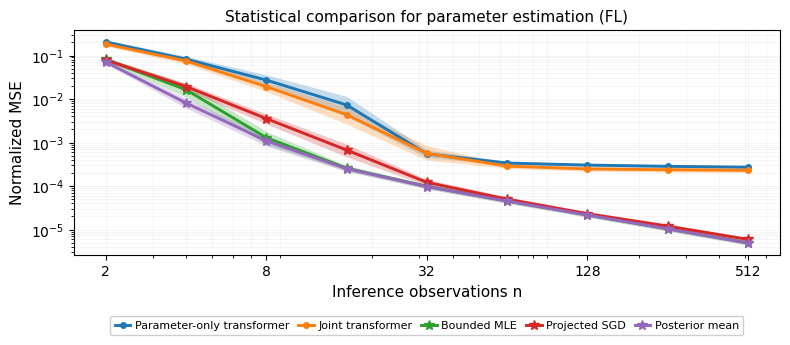

In [146]:
forced_linear_results = compare_family(ROOT, ROWS, 'forced_linear', seeds=SEEDS, ns=INFERENCE_NS, posterior=True, posterior_settings=POSTERIOR_SETTINGS, train_ns=(128,), include_joint=True, **SETTINGS)


Loaded logistic seed=20260906 n=2
  MLE solver success 256/256; median optimality=6.2e-12; SGD median projected gradient=0.0015, objective increased=0/256; fit seconds MLE/SGD=11.4/0.5
Loaded logistic seed=20260906 n=4
  MLE solver success 256/256; median optimality=1.3e-10; SGD median projected gradient=0.0023, objective increased=0/256; fit seconds MLE/SGD=2.0/0.5
Loaded logistic seed=20260906 n=8
  MLE solver success 256/256; median optimality=4.7e-10; SGD median projected gradient=0.0025, objective increased=0/256; fit seconds MLE/SGD=1.7/0.5
Loaded logistic seed=20260906 n=16
  MLE solver success 256/256; median optimality=9.3e-10; SGD median projected gradient=0.0024, objective increased=0/256; fit seconds MLE/SGD=1.6/0.5
Loaded logistic seed=20260906 n=32
  MLE solver success 256/256; median optimality=1.4e-09; SGD median projected gradient=0.0025, objective increased=0/256; fit seconds MLE/SGD=1.6/0.5
Loaded logistic seed=20260906 n=64
  MLE solver success 256/256; median optim

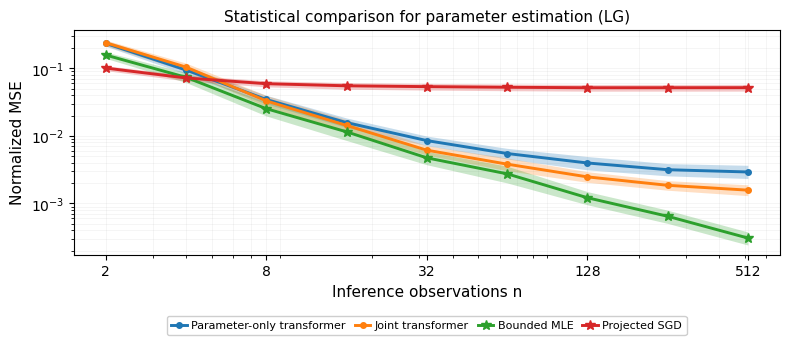

In [147]:
logistic_results = compare_family(ROOT, ROWS, 'logistic', seeds=SEEDS, ns=INFERENCE_NS, posterior=False, posterior_settings=POSTERIOR_SETTINGS, train_ns=(128,), include_joint=True, **SETTINGS)


Loaded birth_death seed=20260906 n=2
  MLE solver success 255/256; median optimality=2.5e-11; SGD median projected gradient=0.00039, objective increased=0/256; fit seconds MLE/SGD=28.8/0.5
Loaded birth_death seed=20260906 n=4
  MLE solver success 256/256; median optimality=1.9e-10; SGD median projected gradient=0.001, objective increased=0/256; fit seconds MLE/SGD=2.4/0.6
Loaded birth_death seed=20260906 n=8
  MLE solver success 256/256; median optimality=5.6e-10; SGD median projected gradient=0.0014, objective increased=0/256; fit seconds MLE/SGD=2.7/0.6
Loaded birth_death seed=20260906 n=16
  MLE solver success 256/256; median optimality=9.4e-10; SGD median projected gradient=0.0015, objective increased=0/256; fit seconds MLE/SGD=2.6/0.6
Loaded birth_death seed=20260906 n=32
  MLE solver success 256/256; median optimality=1.6e-09; SGD median projected gradient=0.0016, objective increased=0/256; fit seconds MLE/SGD=2.6/0.6
Loaded birth_death seed=20260906 n=64
  MLE solver success 256

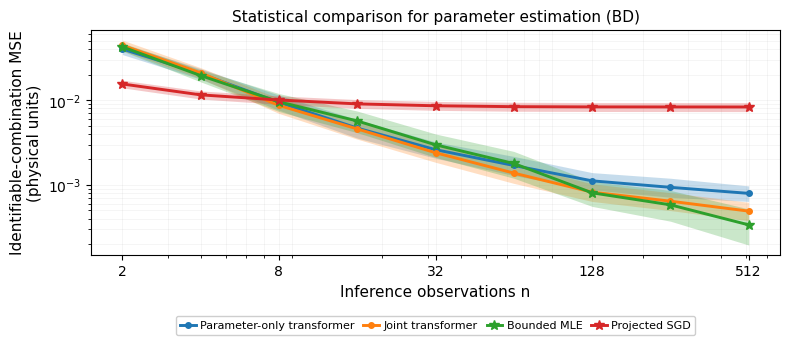

In [148]:
birth_death_results = compare_family(ROOT, ROWS, 'birth_death', seeds=SEEDS, ns=INFERENCE_NS, posterior=False, posterior_settings=POSTERIOR_SETTINGS, train_ns=(128,), include_joint=True, **SETTINGS)


Loaded stuart_landau seed=20260906 n=2
  MLE solver success 256/256; median optimality=5.2e-12; SGD median projected gradient=0.0039, objective increased=0/256; fit seconds MLE/SGD=2.5/0.9
Loaded stuart_landau seed=20260906 n=4
  MLE solver success 256/256; median optimality=8.5e-10; SGD median projected gradient=0.0045, objective increased=0/256; fit seconds MLE/SGD=2.4/0.9
Loaded stuart_landau seed=20260906 n=8
  MLE solver success 256/256; median optimality=1.7e-09; SGD median projected gradient=0.0043, objective increased=0/256; fit seconds MLE/SGD=2.3/1.1
Loaded stuart_landau seed=20260906 n=16
  MLE solver success 256/256; median optimality=2.9e-09; SGD median projected gradient=0.0046, objective increased=0/256; fit seconds MLE/SGD=2.3/1.1
Loaded stuart_landau seed=20260906 n=32
  MLE solver success 256/256; median optimality=4.6e-09; SGD median projected gradient=0.0046, objective increased=0/256; fit seconds MLE/SGD=2.3/1.1
Loaded stuart_landau seed=20260906 n=64
  MLE solver 

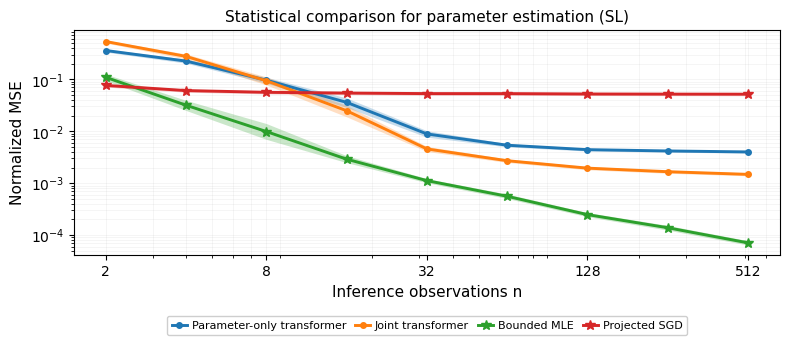

In [149]:
stuart_landau_results = compare_family(ROOT, ROWS, 'stuart_landau', seeds=SEEDS, ns=INFERENCE_NS, posterior=False, posterior_settings=POSTERIOR_SETTINGS, train_ns=(128,), include_joint=True, **SETTINGS)


## Conditional variance across repeated datasets at fixed parameters

For each fixed parameter value, generate independent observation times and Gaussian noise, then compare the fixed n=8 and n=128 parameter transformers with bounded MLE on exactly the same datasets. We plot variance averaged across five fixed parameter values, and then averaged equally across the two training seeds. The variance is computed within each model before averaging, not by pooling predictions from different models. Parameter outputs and variance are in normalized parameter coordinates.

This uses the local best checkpoints under model_weights/. It runs new model inference and MLE fitting, then caches all estimates in statistical_comparison_cache/conditional_variance/. First run can take time: 5 parameters × 128 datasets × 9 n values for each family and seed.

In [150]:
from ode_paper import repeated_variance
import importlib
importlib.reload(repeated_variance)
VARIANCE_NS = (2, 4, 8, 16, 32, 64, 128, 256, 512)
ANCHORS = 5
REPETITIONS = 128
MLE_STARTS = 5
DEVICE = 'cpu'  # Use 'mps' for Apple GPU inference if available.


Loaded cached conditional-variance estimates: forced_linear


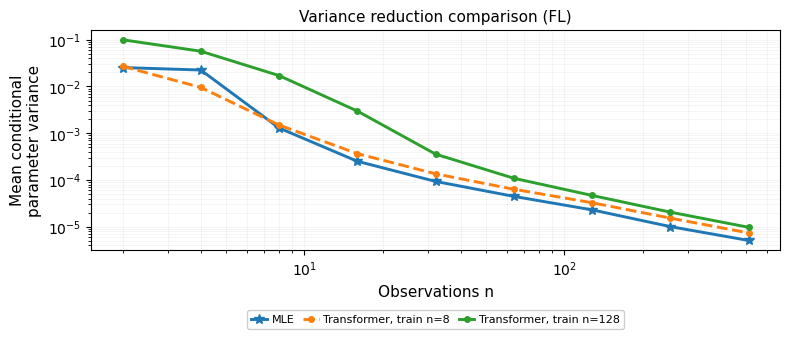

In [151]:
forced_linear_variance_results = repeated_variance.run_family(
    ROOT, 'forced_linear', seeds=SEEDS, ns=VARIANCE_NS, anchors=ANCHORS,
    repetitions=REPETITIONS, mle_starts=MLE_STARTS, device=DEVICE)


Loaded cached conditional-variance estimates: logistic


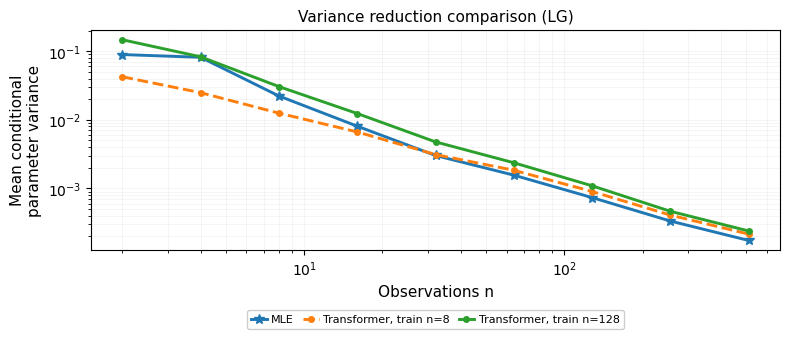

In [152]:
logistic_variance_results = repeated_variance.run_family(
    ROOT, 'logistic', seeds=SEEDS, ns=VARIANCE_NS, anchors=ANCHORS,
    repetitions=REPETITIONS, mle_starts=MLE_STARTS, device=DEVICE)


Loaded cached conditional-variance estimates: stuart_landau


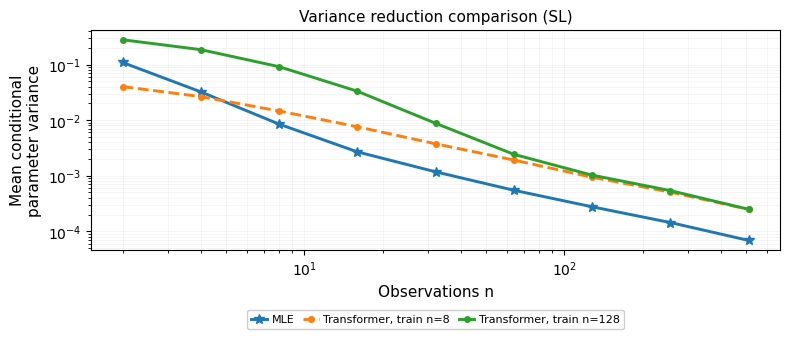

In [153]:
stuart_landau_variance_results = repeated_variance.run_family(
    ROOT, 'stuart_landau', seeds=SEEDS, ns=VARIANCE_NS, anchors=ANCHORS,
    repetitions=REPETITIONS, mle_starts=MLE_STARTS, device=DEVICE)
